In [4]:
# O ruído recebe classe pelos rótulos deste ensaio; não equivale automaticamente a ataque.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


PASTA = Path( "../resultados/ensaio_20261014_194020")

features = pd.read_csv(
    PASTA / "features.csv"
)

avaliacao = pd.read_csv(
    PASTA / "avaliacao.csv"
)

dataset_simples = features.merge(
    avaliacao,
    on="janela",
    validate="one_to_one"
)


COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]

COLUNAS_CONTINUAS = [
    "taxa_requisicoes",
    "latencia_ms"
]


X = dataset_simples[
    COLUNAS_ML
].copy()


scaler = StandardScaler()

X_normalizado = X.copy()

X_normalizado[
    COLUNAS_CONTINUAS
] = scaler.fit_transform(
    X[
        COLUNAS_CONTINUAS
    ]
)


dados_simples = X_normalizado.to_numpy(
    dtype=float
)

In [5]:
def encontrar_atrator(
    ponto,
    dados,
    sigma,
    tolerancia=1e-4,
    max_iteracoes=100
):
    atual = ponto.copy()

    for numero_iteracao in range(
        max_iteracoes
    ):

        diferencas = (
            dados - atual
        )

        distancia_quadrada = np.sum(
            diferencas ** 2,
            axis=1
        )

        pesos = np.exp(
            -distancia_quadrada
            / (2 * sigma ** 2)
        )

        soma_pesos = pesos.sum()

        if soma_pesos == 0:
            break

        novo = (
            pesos[:, None] * dados
        ).sum(axis=0) / soma_pesos

        deslocamento = np.linalg.norm(
            novo - atual
        )

        atual = novo

        if deslocamento < tolerancia:

            densidade = (
                densidade_gaussiana(
                    atual,
                    dados,
                    sigma
                )
            )

            return (
                atual,
                densidade,
                numero_iteracao + 1,
                True
            )

    densidade = densidade_gaussiana(
        atual,
        dados,
        sigma
    )

    return (
        atual,
        densidade,
        max_iteracoes,
        False
    )

In [6]:
def densidade_gaussiana(
    ponto,
    dados,
    sigma
):
    diferencas = (
        dados - ponto
    )

    distancia_quadrada = np.sum(
        diferencas ** 2,
        axis=1
    )

    pesos = np.exp(
        -distancia_quadrada
        / (2 * sigma ** 2)
    )

    dimensoes = dados.shape[1]

    normalizador = (
        len(dados)
        * (np.sqrt(2 * np.pi) * sigma)
        ** dimensoes
    )

    return (
        pesos.sum()
        / normalizador
    )

In [7]:
def calcular_atratores(
    dados,
    sigma
):
    atratores = []
    densidades = []
    iteracoes = []
    convergiu = []

    for ponto in dados:

        (
            atrator,
            densidade,
            numero_iteracoes,
            sucesso
        ) = encontrar_atrator(
            ponto,
            dados,
            sigma
        )

        atratores.append(
            atrator
        )

        densidades.append(
            densidade
        )

        iteracoes.append(
            numero_iteracoes
        )

        convergiu.append(
            sucesso
        )

    return (
        np.array(atratores),
        np.array(densidades),
        np.array(iteracoes),
        np.array(convergiu)
    )

In [8]:
def agrupar_atratores(
    atratores,
    tolerancia=0.05
):
    quantidade = len(atratores)

    pai = list(
        range(quantidade)
    )

    def encontrar(x):

        while pai[x] != x:

            pai[x] = pai[
                pai[x]
            ]

            x = pai[x]

        return x

    def unir(a, b):

        raiz_a = encontrar(a)
        raiz_b = encontrar(b)

        if raiz_a != raiz_b:
            pai[raiz_b] = raiz_a


    for i in range(quantidade):

        distancias = np.linalg.norm(
            atratores[i + 1:]
            - atratores[i],
            axis=1
        )

        proximos = np.where(
            distancias <= tolerancia
        )[0]

        for indice in proximos:

            j = (
                i
                + 1
                + indice
            )

            unir(i, j)


    raizes = [
        encontrar(i)
        for i in range(quantidade)
    ]

    mapa = {}

    labels = np.zeros(
        quantidade,
        dtype=int
    )

    proximo_cluster = 0

    for i, raiz in enumerate(raizes):

        if raiz not in mapa:

            mapa[raiz] = (
                proximo_cluster
            )

            proximo_cluster += 1

        labels[i] = mapa[raiz]

    return labels

In [9]:
def executar_denclue(
    dados,
    sigma,
    xi=0.0,
    tolerancia_atrator=0.05
):
    (
        atratores,
        densidades,
        iteracoes,
        convergiu
    ) = calcular_atratores(
        dados,
        sigma
    )

    labels = np.full(
        len(dados),
        -1,
        dtype=int
    )

    validos = (
        densidades >= xi
    )

    if validos.sum() > 0:

        labels_validos = (
            agrupar_atratores(
                atratores[validos],
                tolerancia_atrator
            )
        )

        labels[
            validos
        ] = labels_validos

    return {
        "labels": labels,
        "atratores": atratores,
        "densidades": densidades,
        "iteracoes": iteracoes,
        "convergiu": convergiu
    }

In [10]:
SIGMAS = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.75,
    1.00
]

In [11]:
resultados_sigma = []

labels_por_sigma = {}


for sigma in SIGMAS:

    print(
        "Executando sigma:",
        sigma
    )

    resultado = executar_denclue(
        dados_simples,
        sigma=sigma,
        xi=0.0
    )

    labels = resultado["labels"]

    labels_por_sigma[
        sigma
    ] = labels


    clusters_validos = sorted(
        set(labels) - {-1}
    )

    quantidade_clusters = len(
        clusters_validos
    )


    if (
        quantidade_clusters >= 2
        and quantidade_clusters
        < len(dados_simples)
    ):

        silhouette = silhouette_score(
            dados_simples,
            labels
        )

    else:

        silhouette = np.nan


    resultados_sigma.append({
        "sigma": sigma,
        "clusters":
            quantidade_clusters,

        "silhouette":
            silhouette,

        "iteracoes_media":
            resultado[
                "iteracoes"
            ].mean(),

        "convergencia":
            resultado[
                "convergiu"
            ].mean() * 100
    })


tabela_sigma_simples = pd.DataFrame(
    resultados_sigma
)

display(
    tabela_sigma_simples.round(4)
)

Executando sigma: 0.1
Executando sigma: 0.15
Executando sigma: 0.2
Executando sigma: 0.25
Executando sigma: 0.3
Executando sigma: 0.4
Executando sigma: 0.5
Executando sigma: 0.75
Executando sigma: 1.0


,sigma,clusters,silhouette,iteracoes_media,convergencia
0,0.10,8,0.5059,34.4357,100.0
1,0.15,4,0.7882,24.9571,100.0
2,0.20,4,0.7882,20.6929,100.0
3,0.25,3,0.8266,18.1286,100.0
4,0.30,3,0.8266,15.2643,100.0
5,0.40,3,0.8266,11.4286,100.0
6,0.50,3,0.8266,9.2929,100.0
7,0.75,3,0.8266,6.6500,100.0
8,1.00,2,0.8905,6.1143,100.0


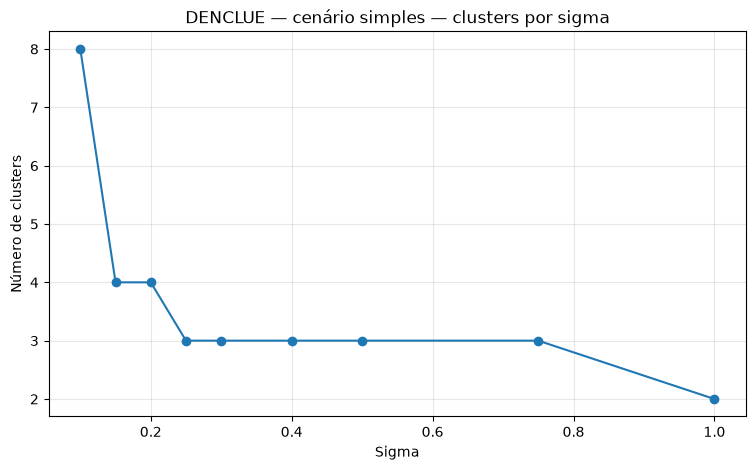

In [12]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_sigma_simples["sigma"],
    tabela_sigma_simples["clusters"],
    marker="o"
)

ax.set_title(
    "DENCLUE — cenário simples — clusters por sigma"
)

ax.set_xlabel(
    "Sigma"
)

ax.set_ylabel(
    "Número de clusters"
)

ax.grid(alpha=0.3)

plt.show()

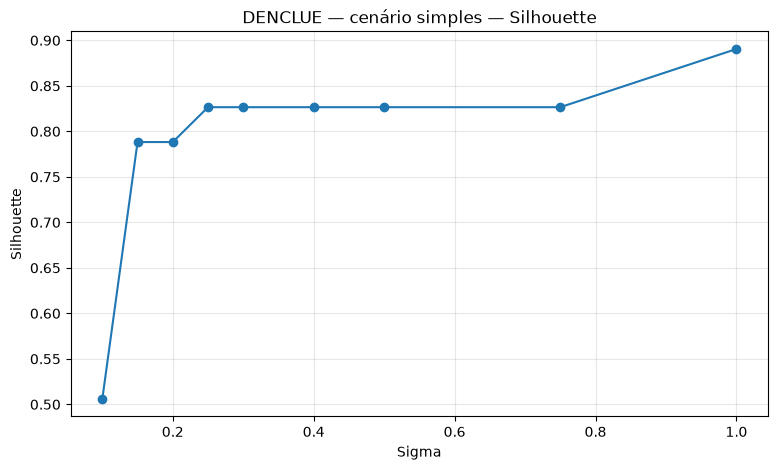

In [13]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_sigma_simples["sigma"],
    tabela_sigma_simples["silhouette"],
    marker="o"
)

ax.set_title(
    "DENCLUE — cenário simples — Silhouette"
)

ax.set_xlabel(
    "Sigma"
)

ax.set_ylabel(
    "Silhouette"
)

ax.grid(alpha=0.3)

plt.show()

In [14]:
SIGMA_SIMPLES = 0.50

resultado_base_simples = executar_denclue(
    dados_simples,
    sigma=SIGMA_SIMPLES,
    xi=0.0
)

atratores_simples = (
    resultado_base_simples["atratores"]
)

densidades_simples = (
    resultado_base_simples["densidades"]
)

In [15]:
labels_base_simples = agrupar_atratores(
    atratores_simples,
    tolerancia=0.05
)

print(
    "Clusters antes do xi:",
    sorted(
        np.unique(
            labels_base_simples
        )
    )
)

Clusters antes do xi: [np.int64(0), np.int64(1), np.int64(2)]


In [16]:
resumo_atratores_simples = []

for cluster in sorted(
    np.unique(labels_base_simples)
):

    mascara = (
        labels_base_simples
        == cluster
    )

    atrator_representante = (
        atratores_simples[
            mascara
        ].mean(axis=0)
    )

    densidade_atrator = (
        densidade_gaussiana(
            atrator_representante,
            dados_simples,
            SIGMA_SIMPLES
        )
    )

    resumo_atratores_simples.append({
        "cluster": cluster,

        "quantidade":
            mascara.sum(),

        "percentual":
            mascara.mean() * 100,

        "densidade_atrator":
            densidade_atrator,

        "taxa_requisicoes":
            atrator_representante[0],

        "latencia_ms":
            atrator_representante[1],

        "latencia_disponivel":
            atrator_representante[2]
    })


tabela_atratores_simples = pd.DataFrame(
    resumo_atratores_simples
)

display(
    tabela_atratores_simples
    .sort_values(
        "densidade_atrator"
    )
    .round(6)
)

,cluster,quantidade,percentual,densidade_atrator,taxa_requisicoes,latencia_ms,latencia_disponivel
1,1,1,0.714286,0.003628,-0.408687,10.542126,1.0
2,2,20,14.285714,0.055450,2.452523,0.289952,1.0
0,0,119,85.000000,0.328391,-0.408151,-0.176343,1.0


In [17]:
densidades_atratores_simples = np.sort(
    tabela_atratores_simples[
        "densidade_atrator"
    ].unique()
)

print(
    densidades_atratores_simples
)

[0.00362821 0.05544953 0.32839107]


In [18]:
candidatos_xi_simples = {
    "sem_limiar": 0.0
}

for i in range(
    len(
        densidades_atratores_simples
    ) - 1
):

    inferior = (
        densidades_atratores_simples[i]
    )

    superior = (
        densidades_atratores_simples[
            i + 1
        ]
    )

    candidatos_xi_simples[
        f"entre_{i}_{i+1}"
    ] = (
        inferior + superior
    ) / 2


display(
    pd.DataFrame(
        candidatos_xi_simples.items(),
        columns=[
            "configuracao",
            "xi"
        ]
    )
)

,configuracao,xi
0,sem_limiar,0.000000
1,entre_0_1,0.029539
2,entre_1_2,0.191920


In [19]:
resultados_xi_simples = []


for nome, xi in (
    candidatos_xi_simples.items()
):

    labels = (
        labels_base_simples.copy()
    )

    clusters_removidos = []


    for _, linha in (
        tabela_atratores_simples
        .iterrows()
    ):

        cluster = int(
            linha["cluster"]
        )

        densidade = (
            linha[
                "densidade_atrator"
            ]
        )


        if densidade < xi:

            labels[
                labels == cluster
            ] = -1

            clusters_removidos.append(
                cluster
            )


    validos = (
        labels != -1
    )

    quantidade_clusters = len(
        set(labels) - {-1}
    )

    ruido = (
        (~validos).mean()
        * 100
    )


    if (
        quantidade_clusters >= 2
        and validos.sum()
        > quantidade_clusters
    ):

        silhouette = silhouette_score(
            dados_simples[
                validos
            ],
            labels[
                validos
            ]
        )

    else:

        silhouette = np.nan


    resultados_xi_simples.append({
        "configuracao": nome,
        "xi": xi,
        "clusters":
            quantidade_clusters,
        "ruido_percentual":
            ruido,
        "silhouette":
            silhouette,
        "clusters_removidos":
            str(clusters_removidos)
    })


tabela_xi_simples = pd.DataFrame(
    resultados_xi_simples
)

display(
    tabela_xi_simples.round(6)
)

,configuracao,xi,clusters,ruido_percentual,silhouette,clusters_removidos
0,sem_limiar,0.000000,3,0.000000,0.826551,[]
1,entre_0_1,0.029539,2,0.714286,0.832497,[1]
2,entre_1_2,0.191920,1,15.000000,NaN,"[1, 2]"


In [20]:
densidades_ordenadas = np.sort(
    tabela_atratores_simples[
        "densidade_atrator"
    ].to_numpy()
)

XI_SIMPLES = (
    densidades_ordenadas[0]
    + densidades_ordenadas[1]
) / 2

print(
    "Sigma:",
    SIGMA_SIMPLES
)

print(
    "Xi:",
    f"{XI_SIMPLES:.15f}"
)

Sigma: 0.5
Xi: 0.029538869390677


In [21]:
labels_denclue_simples = (
    labels_base_simples.copy()
)

for _, linha in (
    tabela_atratores_simples.iterrows()
):

    cluster = int(
        linha["cluster"]
    )

    densidade = (
        linha["densidade_atrator"]
    )

    if densidade < XI_SIMPLES:

        labels_denclue_simples[
            labels_denclue_simples
            == cluster
        ] = -1

In [22]:
display(
    pd.Series(
        labels_denclue_simples
    )
    .value_counts()
    .sort_index()
    .rename("quantidade")
)

-1      1
 0    119
 2     20
Name: quantidade, dtype: int64

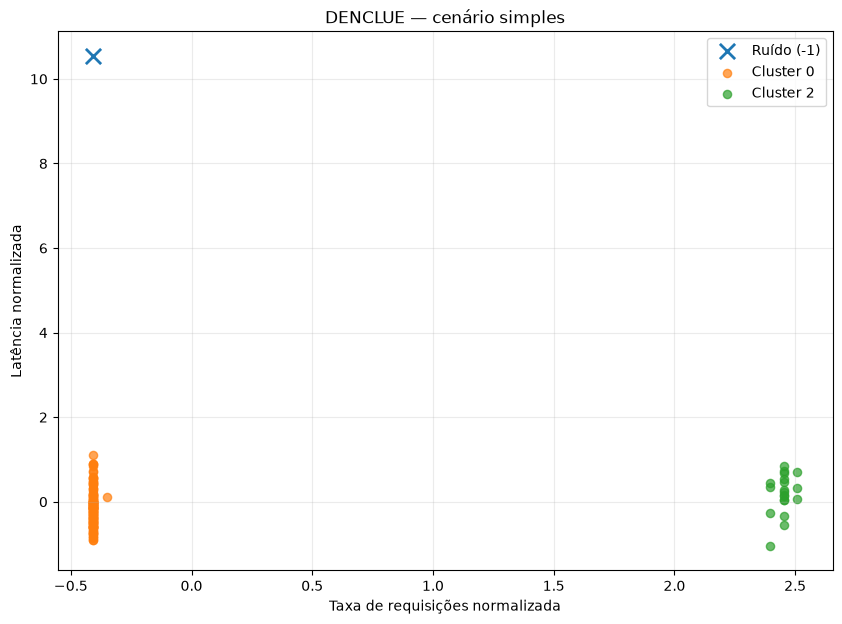

In [23]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

for cluster in sorted(
    np.unique(
        labels_denclue_simples
    )
):

    mascara = (
        labels_denclue_simples
        == cluster
    )

    if cluster == -1:

        ax.scatter(
            X_normalizado.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_normalizado.loc[
                mascara,
                "latencia_ms"
            ],
            marker="x",
            s=120,
            linewidths=2,
            label="Ruído (-1)"
        )

    else:

        ax.scatter(
            X_normalizado.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_normalizado.loc[
                mascara,
                "latencia_ms"
            ],
            s=35,
            alpha=0.7,
            label=f"Cluster {cluster}"
        )


ax.set_title(
    "DENCLUE — cenário simples"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

ax.legend()
ax.grid(alpha=0.25)

plt.show()

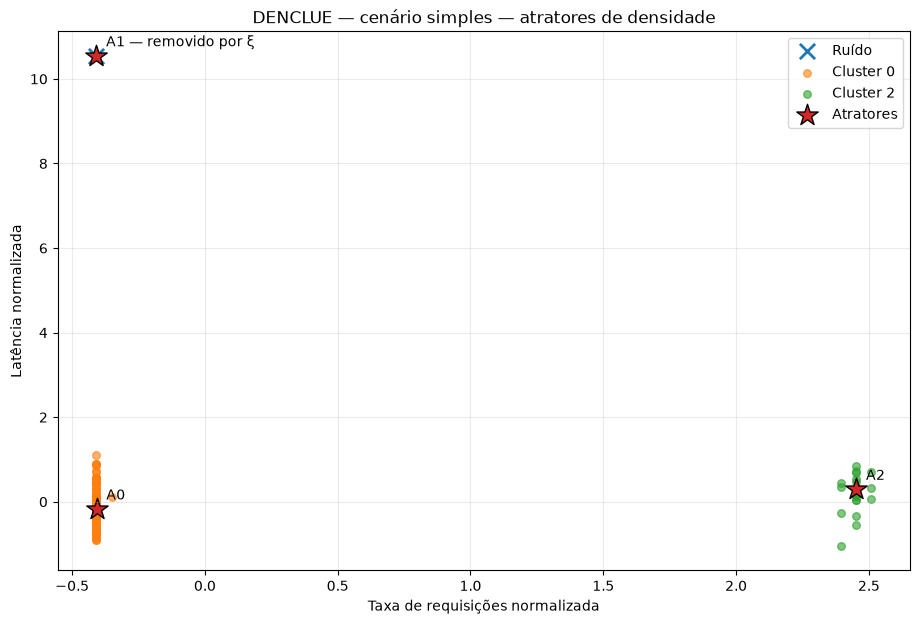

In [24]:
fig, ax = plt.subplots(
    figsize=(11, 7)
)


for cluster in sorted(
    np.unique(
        labels_denclue_simples
    )
):

    mascara = (
        labels_denclue_simples
        == cluster
    )

    if cluster == -1:

        ax.scatter(
            X_normalizado.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_normalizado.loc[
                mascara,
                "latencia_ms"
            ],
            marker="x",
            s=120,
            linewidths=2,
            label="Ruído"
        )

    else:

        ax.scatter(
            X_normalizado.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_normalizado.loc[
                mascara,
                "latencia_ms"
            ],
            s=30,
            alpha=0.6,
            label=f"Cluster {cluster}"
        )


ax.scatter(
    tabela_atratores_simples[
        "taxa_requisicoes"
    ],
    tabela_atratores_simples[
        "latencia_ms"
    ],
    marker="*",
    s=260,
    edgecolors="black",
    linewidths=1,
    label="Atratores"
)


for _, linha in (
    tabela_atratores_simples.iterrows()
):

    texto = (
        f"A{int(linha['cluster'])}"
    )

    if (
        linha["densidade_atrator"]
        < XI_SIMPLES
    ):
        texto += " — removido por ξ"

    ax.annotate(
        texto,
        (
            linha["taxa_requisicoes"],
            linha["latencia_ms"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )


ax.set_title(
    "DENCLUE — cenário simples — atratores de densidade"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

ax.legend()
ax.grid(alpha=0.25)

plt.show()

In [25]:
resultado_denclue_simples = (
    dataset_simples[
        [
            "janela",
            "label",
            "fase"
        ]
    ]
    .copy()
)

resultado_denclue_simples[
    "cluster"
] = labels_denclue_simples

In [26]:
display(
    pd.crosstab(
        resultado_denclue_simples[
            "cluster"
        ],
        resultado_denclue_simples[
            "fase"
        ]
    )
)

fase,carga,normal,recuperacao
cluster,,,
-1,0,1,0
0,1,59,59
2,20,0,0


In [27]:
composicao_denclue_simples = (
    pd.crosstab(
        resultado_denclue_simples[
            "cluster"
        ],
        resultado_denclue_simples[
            "fase"
        ],
        normalize="index"
    ) * 100
)

display(
    composicao_denclue_simples
    .round(2)
)

fase,carga,normal,recuperacao
cluster,,,
-1,0.00,100.00,0.00
0,0.84,49.58,49.58
2,100.00,0.00,0.00


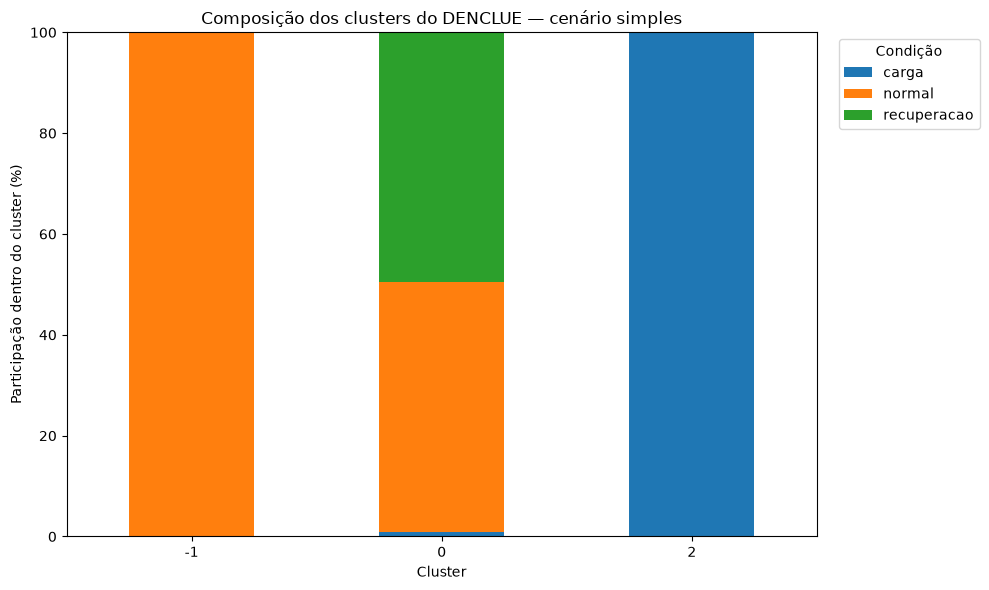

In [28]:
composicao_denclue_simples.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title(
    "Composição dos clusters do DENCLUE — cenário simples"
)

plt.xlabel("Cluster")

plt.ylabel(
    "Participação dentro do cluster (%)"
)

plt.legend(
    title="Condição",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

In [29]:
tabela_label_denclue = pd.crosstab(
    resultado_denclue_simples[
        "cluster"
    ],
    resultado_denclue_simples[
        "label"
    ]
)

display(
    tabela_label_denclue
)

label,0,1
cluster,,
-1,1,0
0,118,1
2,0,20


In [30]:
proporcao_ataque_denclue = (
    resultado_denclue_simples
    .groupby("cluster")[
        "label"
    ]
    .mean()
)

display(
    (
        proporcao_ataque_denclue
        * 100
    )
    .round(2)
    .rename(
        "percentual_ataque"
    )
)

cluster
-1      0.00
 0      0.84
 2    100.00
Name: percentual_ataque, dtype: float64

In [31]:
MAPA_DENCLUE_SIMPLES = {
    cluster:
        int(proporcao > 0.50)

    for cluster, proporcao
    in proporcao_ataque_denclue.items()
}

print(
    MAPA_DENCLUE_SIMPLES
)

{-1: 0, 0: 0, 2: 1}


In [32]:
resultado_denclue_simples[
    "previsao"
] = (
    resultado_denclue_simples[
        "cluster"
    ]
    .map(
        MAPA_DENCLUE_SIMPLES
    )
)

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


y_real = (
    resultado_denclue_simples[
        "label"
    ]
)

y_previsto = (
    resultado_denclue_simples[
        "previsao"
    ]
)


print(
    "Acurácia:",
    round(
        accuracy_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "Precisão:",
    round(
        precision_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_real,
            y_previsto
        ),
        4
    )
)

print(
    "F1:",
    round(
        f1_score(
            y_real,
            y_previsto
        ),
        4
    )
)

Acurácia: 0.9929
Precisão: 1.0
Recall: 0.9524
F1: 0.9756


In [34]:
matriz_denclue_simples = (
    confusion_matrix(
        y_real,
        y_previsto
    )
)

display(
    pd.DataFrame(
        matriz_denclue_simples,

        index=[
            "Real legítimo",
            "Real ataque"
        ],

        columns=[
            "Previsto legítimo",
            "Previsto ataque"
        ]
    )
)

,Previsto legítimo,Previsto ataque
Real legítimo,119,0
Real ataque,1,20


In [35]:
import pandas as pd
import matplotlib.pyplot as plt


comparacao_final = pd.DataFrame({
    "Cenário": [
        "Simples",
        "Simples",
        "Realista",
        "Realista"
    ],

    "Algoritmo": [
        "K-Means",
        "DENCLUE",
        "K-Means",
        "DENCLUE"
    ],

    "Acurácia": [
        0.9929,
        0.9929,
        0.7796,
        0.7722
    ],

    "Precisão": [
        1.0000,
        1.0000,
        0.7254,
        1.0000
    ],

    "Recall": [
        0.9524,
        0.9524,
        0.5628,
        0.3279
    ],

    "F1": [
        0.9756,
        0.9756,
        0.6338,
        0.4938
    ]
})

display(
    comparacao_final
)

,Cenário,Algoritmo,Acurácia,Precisão,Recall,F1
0,Simples,K-Means,0.9929,1.0000,0.9524,0.9756
1,Simples,DENCLUE,0.9929,1.0000,0.9524,0.9756
2,Realista,K-Means,0.7796,0.7254,0.5628,0.6338
3,Realista,DENCLUE,0.7722,1.0000,0.3279,0.4938


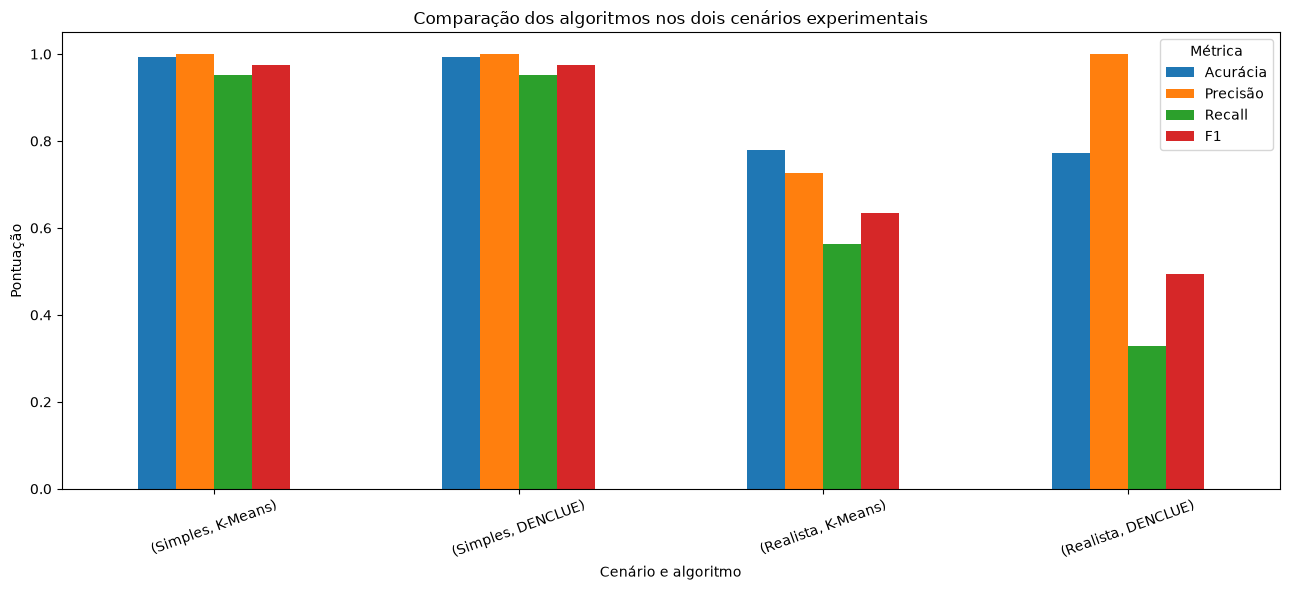

In [36]:
grafico = (
    comparacao_final
    .set_index(
        ["Cenário", "Algoritmo"]
    )[
        [
            "Acurácia",
            "Precisão",
            "Recall",
            "F1"
        ]
    ]
)

ax = grafico.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title(
    "Comparação dos algoritmos nos dois cenários experimentais"
)

ax.set_ylabel(
    "Pontuação"
)

ax.set_xlabel(
    "Cenário e algoritmo"
)

ax.set_ylim(
    0,
    1.05
)

plt.xticks(
    rotation=20
)

plt.legend(
    title="Métrica"
)

plt.tight_layout()

plt.show()